# EquityVista — Results: ARIMA vs LSTM vs RandomForest vs Ensemble
Full pipeline for **PTT.BK**: data → indicators → three models → metrics → ensemble → next-day forecast.

**Time-series rules followed throughout**
1. Chronological 80/20 split, never shuffled.
2. Scalers are fit on the **training** part only.
3. Every model predicts a *future* value from *past* information only (see the data-leakage note in the RF section).

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath(".."))   # repo root, so `import config`, `src.*` work
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import config as cfg
from src.fetch import fetch_data
from src.features import add_indicators
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": .3})
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.arima.model import ARIMA
from src.models.arima import fit_predict
from src.features import make_sequences
from src.models.lstm import train_lstm
from src.models.rf_classifier import make_direction, train_rf
from src.ensemble import aggregate
from src.evaluate import regression_metrics, clf_metrics
np.random.seed(cfg.SEED); tf.random.set_seed(cfg.SEED)

raw = fetch_data(cfg.TICKER, cfg.START, cfg.END)
df = add_indicators(raw)
n = len(df)
print(f"{n} rows, {df.index[0].date()} -> {df.index[-1].date()}")

2137 rows, 2016-03-14 -> 2024-12-30


## 1. ARIMA baseline
**What was changed vs. the raw-price `(5,1,0)` fit:**
- Fit on `log1p(Close)` and invert with `expm1` — this guarantees positive prices and intervals. Orders `(5,1,0)`, `(1,1,0)`, `(0,1,0)` gave near-identical AIC and no warnings, so `(5,1,0)` is kept.
- The very wide interval `[6.9, 43.8]` was **not** a scale problem: it is the 95% CI of a *428-step-ahead* forecast, and ARIMA uncertainty grows with the horizon (log1p alone does not remove it — see the check below). The app shows a **next-day** forecast, so evaluation uses **rolling one-step-ahead** forecasts: parameters are estimated on the training set only, then the model filters through the test days (`apply`) so each prediction uses only data up to the previous day. This gives sane, narrow intervals and a fair comparison with the LSTM (which also predicts one day ahead from true history).

In [2]:
log_close = np.log1p(df["Close"])
ar = fit_predict(log_close, cfg.TEST_SPLIT, order=(5, 1, 0))
cut_a = int(n * cfg.TEST_SPLIT)

# (a) the multi-step view, for reference: the long-horizon 95% CI is wide by construction
lo_m, hi_m = np.expm1(ar["test_conf"][-1])
print(f"Multi-step ({n-cut_a}-day horizon) forecast: {np.expm1(ar['next']):.2f}  95% CI [{lo_m:.2f}, {hi_m:.2f}]  <- horizon effect")

# (b) rolling one-step-ahead with parameters frozen from the training fit
res = ar["model"].apply(log_close.values)
pr = res.get_prediction(start=cut_a)
arima_pred = pd.Series(np.expm1(pr.predicted_mean), index=df.index[cut_a:])
ci = np.expm1(pr.conf_int(alpha=0.05))
arima_lo = pd.Series(ci[:, 0], index=df.index[cut_a:]); arima_hi = pd.Series(ci[:, 1], index=df.index[cut_a:])
print("One-step 95%% interval width (THB): mean %.2f | lowest lo %.2f | highest hi %.2f" % ((arima_hi-arima_lo).mean(), arima_lo.min(), arima_hi.max()))

Multi-step (428-day horizon) forecast: 25.55  95% CI [12.65, 50.65]  <- horizon effect
One-step 95% interval width (THB): mean 1.96 | lowest lo 23.88 | highest hi 32.18


## 2. LSTM (features and target normalised)
`make_sequences` builds windows of 60 days × 6 features that predict the **next** day's Close. The sequence split is chronological 80/20. A `MinMaxScaler` is fit on the **training** windows only (features) and on the training targets (target); the test set is only transformed. Predictions are inverse-transformed back to THB before computing metrics.

In [3]:
X, y = make_sequences(df, cfg.WINDOW)
seq_dates = df.index[cfg.WINDOW:]
cut_s = int(len(X) * cfg.TEST_SPLIT)
X_tr, X_te, y_tr, y_te = X[:cut_s], X[cut_s:], y[:cut_s], y[cut_s:]

fx = MinMaxScaler().fit(X_tr.reshape(-1, X.shape[2]))      # train only
fy = MinMaxScaler().fit(y_tr.reshape(-1, 1))               # train only
sx = lambda a: fx.transform(a.reshape(-1, a.shape[2])).reshape(a.shape)
X_tr_s, X_te_s = sx(X_tr), sx(X_te)
y_tr_s, y_te_s = fy.transform(y_tr.reshape(-1, 1)).ravel(), fy.transform(y_te.reshape(-1, 1)).ravel()
print("train/test sequences:", X_tr.shape, X_te.shape, "| test starts", seq_dates[cut_s].date())

train/test sequences: (1661, 60, 6) (416, 60, 6) | test starts 2023-04-17


Epochs actually run (max 80, EarlyStopping patience=5): 32


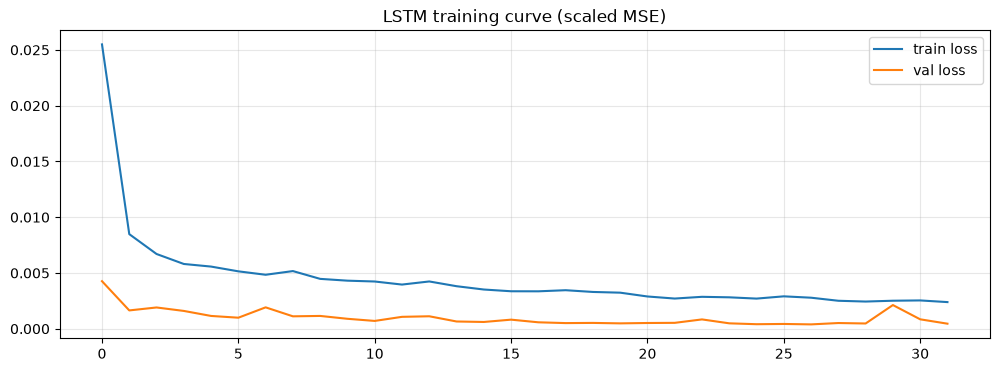

In [4]:
lstm = train_lstm(X_tr_s, y_tr_s, X_te_s, y_te_s, epochs=80)
hist = lstm["history"].history
epochs_run = len(hist["loss"])
print("Epochs actually run (max 80, EarlyStopping patience=5):", epochs_run)
lstm_pred = fy.inverse_transform(lstm["test_pred"].reshape(-1, 1)).ravel()   # back to THB
lstm_s = pd.Series(lstm_pred, index=seq_dates[cut_s:])
plt.plot(hist["loss"], label="train loss"); plt.plot(hist["val_loss"], label="val loss")
plt.title("LSTM training curve (scaled MSE)"); plt.legend(); plt.show()

## 3. RandomForest — next-day direction (and the data-leakage fix)
**Leakage trap:** `make_direction(close)[t]` is the direction of the move *into* day `t` (`close_t − close_{t−1}`). The feature `Return_t` is that very same move, so pairing feature row `t` with label `t` lets the forest simply read the answer (~100% fake accuracy; honest accuracy is ~34%).

**Fix:** the label for feature row `t` is the direction of `close_{t+1} − close_t`, i.e. the label array shifted by −1. The last feature row has no label (tomorrow is unknown): it is dropped from training and used for the *real* next-day forecast. The split stays chronological (`shuffle=False` inside `train_rf`).

In [5]:
feat_cols = ["Close", "Return", "MA20", "MA50", "RSI", "MACD", "Signal"]
X_all = df[feat_cols].values
dir_same_day = make_direction(df["Close"].values)      # dir[t] = sign(close_t - close_{t-1})
y_next = dir_same_day[1:]                              # label for row t = dir[t+1] = sign(close_{t+1} - close_t)
X_rf = X_all[:-1]                                      # drop the last row consistently
assert len(X_rf) == len(y_next)

# leak check: with unshifted labels, "sign of Return" reproduces the label (almost) perfectly
leak_unshifted = np.mean(np.where(X_all[:, 1] > 1e-6, 1, np.where(X_all[:, 1] < -1e-6, 2, 0)) == dir_same_day)
leak_shifted = np.mean(np.where(X_rf[:, 1] > 1e-6, 1, np.where(X_rf[:, 1] < -1e-6, 2, 0)) == y_next)
print("Return-sign rule accuracy  unshifted labels: %.3f (leak)  |  next-day labels: %.3f" % (leak_unshifted, leak_shifted))

rf = train_rf(X_rf, y_next, test_size=1 - cfg.TEST_SPLIT, seed=cfg.SEED)
rf_m = clf_metrics(rf["y_test"], rf["y_pred"])
print("RF test accuracy: %.3f | majority-class baseline: %.3f" % (rf_m["accuracy"], pd.Series(rf["y_test"]).value_counts(normalize=True).max()))
names = {0: "flat", 1: "up", 2: "down"}
cm = pd.DataFrame(rf_m["confusion_matrix"], index=[f"true {names[c]}" for c in sorted(set(rf["y_test"]) | set(rf["y_pred"]))],
                  columns=[f"pred {names[c]}" for c in sorted(set(rf["y_test"]) | set(rf["y_pred"]))])
cm

Return-sign rule accuracy  unshifted labels: 1.000 (leak)  |  next-day labels: 0.366


RF test accuracy: 0.339 | majority-class baseline: 0.379


,pred flat,pred up,pred down
true flat,19,49,94
true up,13,41,82
true down,12,33,85


## 4. Metrics on a common test window
ARIMA, LSTM and a naive baseline are scored on the **same dates** (the LSTM test period). The naive baseline "tomorrow = today's close" is added as a reference: a price model that cannot beat it has not learned anything useful beyond persistence.

In [6]:
common = lstm_s.index
actual = df["Close"].reindex(common)
assert np.allclose(actual.values, y_te), "alignment check"
m_arima = regression_metrics(actual, arima_pred.reindex(common))
m_lstm  = regression_metrics(actual, lstm_pred)
m_naive = regression_metrics(actual, df["Close"].shift(1).reindex(common))
print("Common test window:", common[0].date(), "->", common[-1].date(), f"({len(common)} days)")

Common test window: 2023-04-17 -> 2024-12-30 (416 days)


## 5. Ensemble and next-day forecast
All three components are re-evaluated for the **next trading day**, using data up to the last available day:
- ARIMA: refit on the full history, 1-step forecast + 95% CI (back-transformed with `expm1`).
- LSTM: the latest 60-day window, scaled with the training scalers, prediction inverse-transformed.
- RF: class probabilities for the last feature row (the one with no label yet).

`aggregate` takes the RF class with the highest probability as direction/confidence, blends ARIMA (0.6) and LSTM (0.4) for the price, and reports the ARIMA interval.

In [7]:
full = ARIMA(log_close.values, order=(5, 1, 0)).fit()
fc = full.get_forecast(1)
arima_next = float(np.expm1(fc.predicted_mean[0])); arima_ci = np.expm1(fc.conf_int(alpha=0.05))      # shape (1, 2)

last_win = df[["Close", "Return", "MA20", "MA50", "RSI", "MACD"]].values[-cfg.WINDOW:][None]
lstm_next = float(fy.inverse_transform(lstm["model"].predict(sx(last_win), verbose=0))[0, 0])

rf_probs_next = rf["model"].predict_proba(X_all[-1:])

ens = aggregate(rf_probs_next, rf["classes"], np.array([lstm_next]), None, np.array([arima_next]), arima_ci)
print("ARIMA next:", round(arima_next, 3), "| LSTM next:", round(lstm_next, 3))
print("RF class probs:", dict(zip([names[int(c)] for c in rf["classes"]], rf_probs_next[0].round(3))))
ens

ARIMA next: 28.411 | LSTM next: 28.338
RF class probs: {'flat': np.float64(0.3), 'up': np.float64(0.22), 'down': np.float64(0.48)}


{'direction': 'down',
 'confidence': 0.48,
 'price_pred': 28.382055312215677,
 'interval': [27.51689935494317, 29.333970371373642]}

## 6. Comparison table
Regression metrics are in THB / %; `accuracy` is next-day direction accuracy (3 classes: up / down / flat, chance ≈ 33–40%). Metrics a model does not produce are `NaN`. The ensemble row has no new test metrics of its own: its price is a ARIMA/LSTM blend and its direction is the RF's, so it inherits the RF accuracy and the blended price error is computed on the test window.

In [8]:
blend = 0.6 * arima_pred.reindex(common).values + 0.4 * lstm_pred       # same weights aggregate() uses
m_ens = regression_metrics(actual, blend)
table = pd.DataFrame(
    {"MAE": [m_arima["MAE"], m_lstm["MAE"], np.nan, m_ens["MAE"], m_naive["MAE"]],
     "RMSE": [m_arima["RMSE"], m_lstm["RMSE"], np.nan, m_ens["RMSE"], m_naive["RMSE"]],
     "MAPE (%)": [m_arima["MAPE"], m_lstm["MAPE"], np.nan, m_ens["MAPE"], m_naive["MAPE"]],
     "accuracy": [np.nan, np.nan, rf_m["accuracy"], rf_m["accuracy"], np.nan]},
    index=["ARIMA", "LSTM", "RF (direction acc)", "Ensemble", "Naive (prev. close) — reference"])
table.round(4)

,MAE,RMSE,MAPE (%),accuracy
ARIMA,0.2125,0.3038,0.7436,NaN
LSTM,0.3078,0.4158,1.0755,NaN
RF (direction acc),NaN,NaN,NaN,0.3388
Ensemble,0.2379,0.3244,0.8321,0.3388
Naive (prev. close) — reference,0.2067,0.3035,0.7236,NaN


**Reading the table.** ARIMA with frozen parameters behaves almost like the persistence baseline (daily prices are close to a random walk), so a small MAE gap to the naive row is expected. The LSTM's error is compared on the same days. The RF direction accuracy should be judged against the majority-class baseline printed above: next-day stock direction is nearly unpredictable, and an honest accuracy only slightly above chance is the correct outcome once leakage is removed.

## 7. Actual vs predicted — last 60 test days (ARIMA 95% interval shaded)

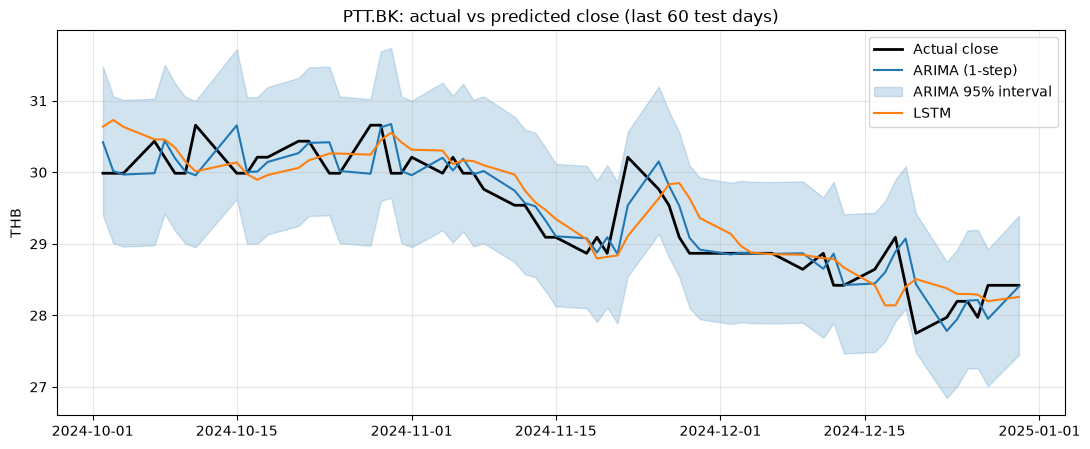

In [9]:
last = common[-60:]
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(last, actual.reindex(last), "k-", lw=2, label="Actual close")
ax.plot(last, arima_pred.reindex(last), "tab:blue", label="ARIMA (1-step)")
ax.fill_between(last, arima_lo.reindex(last), arima_hi.reindex(last), color="tab:blue", alpha=.2, label="ARIMA 95% interval")
ax.plot(last, lstm_s.reindex(last), "tab:orange", label="LSTM")
ax.set_title(f"{cfg.TICKER}: actual vs predicted close (last 60 test days)"); ax.set_ylabel("THB"); ax.legend(); plt.show()

## 8. Next-day forecast

In [10]:
next_date = df.index[-1] + pd.offsets.BDay(1)    # weekends skipped; Thai exchange holidays not modelled
lo, hi = ens["interval"]
print("=" * 52)
print(f"  NEXT-DAY FORECAST — {cfg.TICKER}")
print("=" * 52)
print(f"  Date                : {next_date.date()}")
print(f"  Last close          : {df['Close'].iloc[-1]:.2f} THB ({df.index[-1].date()})")
print(f"  Predicted price     : {ens['price_pred']:.2f} THB  (0.6 ARIMA + 0.4 LSTM)")
print(f"  Predicted direction : {ens['direction'].upper()}")
print(f"  Confidence          : {ens['confidence'] * 100:.1f} %  (RF class probability)")
print(f"  95% interval        : [{lo:.2f}, {hi:.2f}] THB  (ARIMA, 1-day ahead)")
print("=" * 52)
print("  Educational project — not financial advice.")

  NEXT-DAY FORECAST — PTT.BK
  Date                : 2024-12-31
  Last close          : 28.42 THB (2024-12-30)
  Predicted price     : 28.38 THB  (0.6 ARIMA + 0.4 LSTM)
  Predicted direction : DOWN
  Confidence          : 48.0 %  (RF class probability)
  95% interval        : [27.52, 29.33] THB  (ARIMA, 1-day ahead)
  Educational project — not financial advice.
